In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root_path = "/Net/Groups/BSI/work_scratch/ppapastefanou/driver_data/ISIMIP_3b/QUINCY_ready"

In [36]:
file_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai.dat"

# 1. Extract and save ONLY the second row (0-indexed as row 1)
# skiprows=1 skips the header, nrows=1 reads just the target row
second_row = pd.read_csv(file_path, sep=r"\s+", skiprows=1, nrows=1, header=None).squeeze()

# 2. Read the main data, skipping the second row
# skiprows=[1] specifically targets the second row to be ignored
df = pd.read_csv(file_path, sep=r"\s+", skiprows=[1])

In [37]:
df.columns

Index(['year', 'doy', 'hour', 'swvis_srf_down', 'lw_srf_down', 't_min',
       't_max', 'q_air', 'press_srf', 'rain', 'snow', 'wind_air',
       'co2_mixing_ratio', 'co2_dC13', 'co2DC14', 'nhx_srf_down',
       'noy_srf_down', 'p_srf_down'],
      dtype='object')

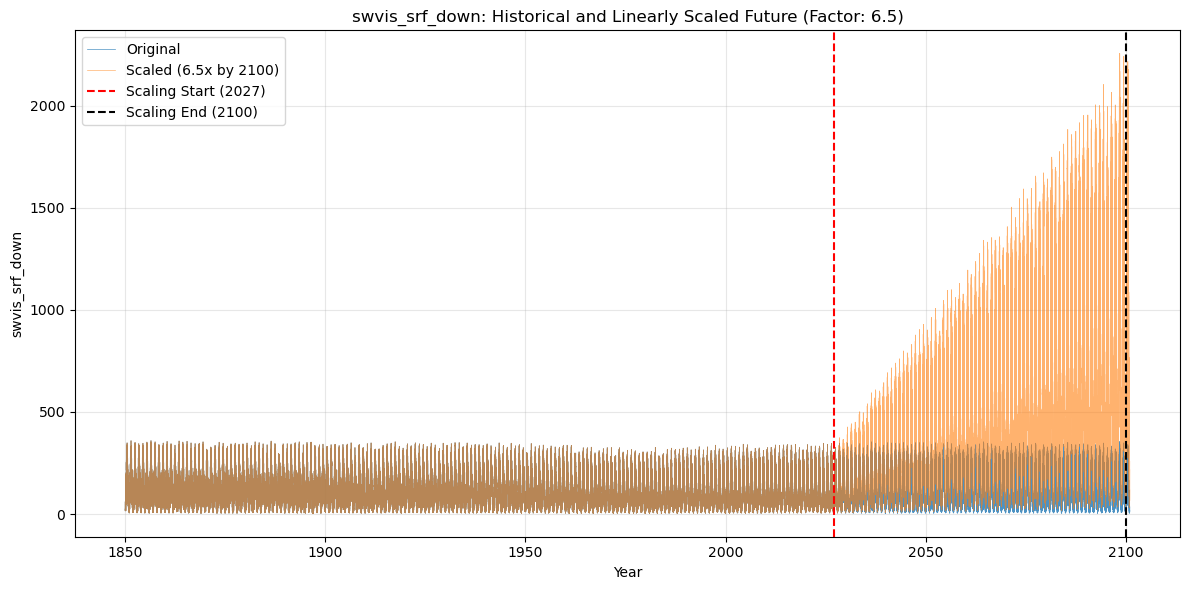

In [38]:
# 1. Create a distinct copy to keep the original untouched
df_scaled = df.copy()

# --- Configuration Variables ---
start_year = 2027
end_year = 2100
target_factor = 6.5  # Set your desired final multiplier here (e.g., 2.5 = 250%)
# -------------------------------

# 1. Calculate the fractional progress between start and end year (0.0 at 2027, 1.0 at 2100)
progress = (df_scaled['year'] - start_year) / (end_year - start_year)

# 2. Scale the progress by the total desired change 
# (e.g., if target_factor is 2.5, the total change is 1.5)
raw_multiplier = 1.0 + (progress * (target_factor - 1.0))

# 3. Clip the values to ensure it stays flat before start_year and after end_year
# Using min/max allows this to work for both increasing and decreasing factors
lower_bound = min(1.0, target_factor)
upper_bound = max(1.0, target_factor)
df_scaled['scaling_factor'] = np.clip(raw_multiplier, lower_bound, upper_bound)

# 4. Apply the scaling to the target variable
df_scaled['swvis_srf_down'] = df['swvis_srf_down'] * df_scaled['scaling_factor']
df_scaled['lw_srf_down'] = df['lw_srf_down'] * df_scaled['scaling_factor']

# Create a continuous time axis for cleaner plotting
df_scaled['decimal_year'] = df_scaled['year'] + (df_scaled['doy'] - 1) / 365.25

# --- Plotting ---
plt.figure(figsize=(12, 6))
plt.plot(df_scaled['decimal_year'], df['swvis_srf_down'], label='Original', alpha=0.8, linewidth=0.5)

# Dynamic label to reflect your chosen variable
plt.plot(df_scaled['decimal_year'], df_scaled['swvis_srf_down'], 
         label=f'Scaled ({target_factor}x by {end_year})', alpha=0.6, linewidth=0.5)

plt.title(f'swvis_srf_down: Historical and Linearly Scaled Future (Factor: {target_factor})')
plt.xlabel('Year')
plt.ylabel('swvis_srf_down')
plt.axvline(x=start_year, color='red', linestyle='--', label=f'Scaling Start ({start_year})')
plt.axvline(x=end_year, color='black', linestyle='--', label=f'Scaling End ({end_year})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# 1. Drop the temporary columns used for math and plotting
df_out = df_scaled.drop(columns=['scaling_factor', 'decimal_year'])

# 2. Convert the saved 'second_row' back into a 1-row DataFrame.
# By explicitly giving it the same column names as df_out, they will stack perfectly.
unit_row_df = pd.DataFrame([second_row.values], columns=df_out.columns)

# 3. Concatenate the unit row on top of the modified data
# This briefly converts the numeric columns to "object" types, which is fine for exporting to text.
final_df = pd.concat([unit_row_df, df_out], ignore_index=True)

# 4. Export to a new file with a whitespace delimiter (a single space)
# index=False ensures pandas doesn't write row numbers into the file
output_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai_mercury_rad.dat"
final_df.to_csv(output_path, sep=" ", index=False)

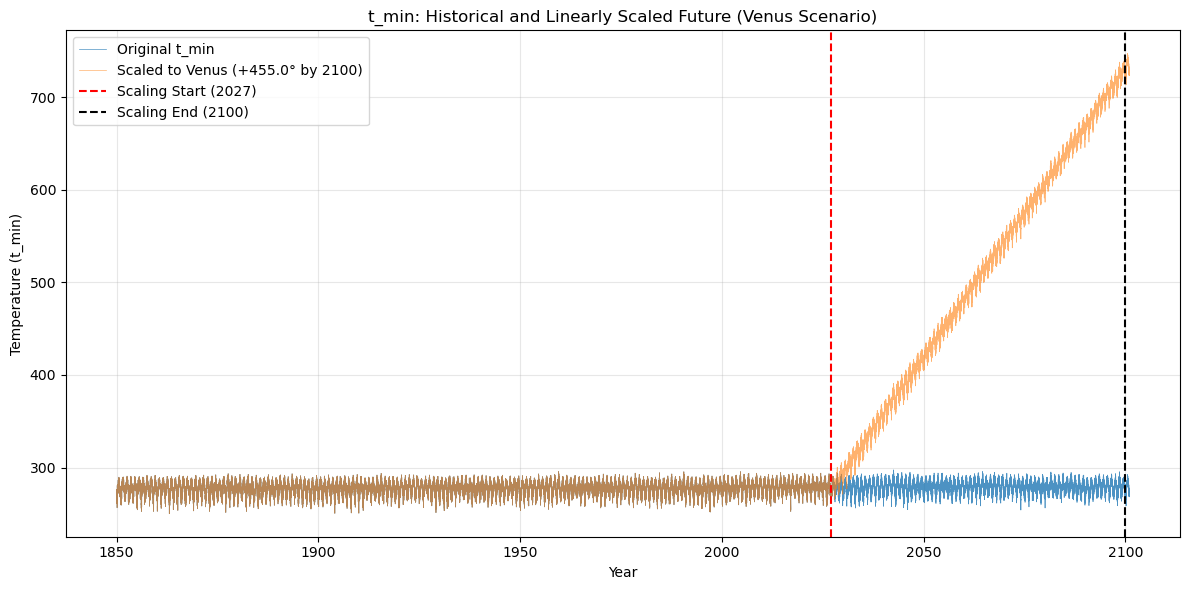

In [39]:
df_scaled = df.copy()

# --- Configuration Variables ---
start_year = 2027
end_year = 2100

# Venus averages ~464°C. 
# Assuming your forcing data is in Celsius and DE-Hai averages ~9°C:
target_increase = 455.0  

# (Note: If your dataset is actually in Kelvin, DE-Hai is ~282K and Venus is ~737K, 
# so your target_increase would be exactly the same: ~455.0 degrees)
# -------------------------------

# 1. Calculate the fractional progress
progress = (df_scaled['year'] - start_year) / (end_year - start_year)

# 2. Clip the progress between 0.0 and 1.0
# This perfectly flatlines the addition to 0 before 2027, and holds it at max after 2100
progress_clipped = np.clip(progress, 0.0, 1.0)

# 3. Calculate the dynamic offset
df_scaled['temp_offset'] = progress_clipped * target_increase

# 4. Apply the offset (Adding instead of multiplying)
df_scaled['t_min'] = df['t_min'] + df_scaled['temp_offset']
df_scaled['t_max'] = df['t_max'] + df_scaled['temp_offset']

# Create a continuous time axis for cleaner plotting
df_scaled['decimal_year'] = df_scaled['year'] + (df_scaled['doy'] - 1) / 365.25

# --- Plotting ---
plt.figure(figsize=(12, 6))

# Plotting original and scaled t_min
plt.plot(df_scaled['decimal_year'], df['t_min'], label='Original t_min', alpha=0.8, linewidth=0.5)

plt.plot(df_scaled['decimal_year'], df_scaled['t_min'], 
         label=f'Scaled to Venus (+{target_increase}° by {end_year})', alpha=0.6, linewidth=0.5)

# Fixed Titles and Labels
plt.title(f't_min: Historical and Linearly Scaled Future (Venus Scenario)')
plt.xlabel('Year')
plt.ylabel('Temperature (t_min)')
plt.axvline(x=start_year, color='red', linestyle='--', label=f'Scaling Start ({start_year})')
plt.axvline(x=end_year, color='black', linestyle='--', label=f'Scaling End ({end_year})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# --- Exporting ---
# 1. Drop the temporary columns used for math and plotting
df_out = df_scaled.drop(columns=['temp_offset', 'decimal_year'])

# 2. Convert the saved 'second_row' back into a 1-row DataFrame.
unit_row_df = pd.DataFrame([second_row.values], columns=df_out.columns)

# 3. Concatenate the unit row on top of the modified data
final_df = pd.concat([unit_row_df, df_out], ignore_index=True)

# 4. Export to a new file with a whitespace delimiter
output_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai_tmin_max_venus.dat"
final_df.to_csv(output_path, sep=" ", index=False)

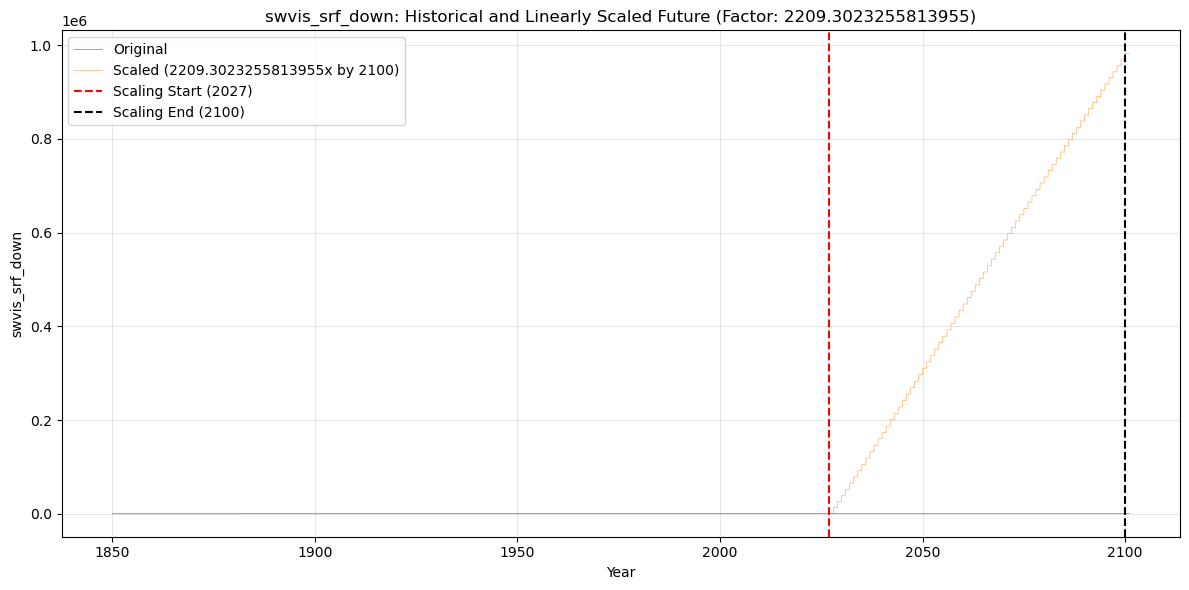

In [40]:
# 1. Create a distinct copy to keep the original untouched
df_scaled = df.copy()

# --- Configuration Variables ---
start_year = 2027
end_year = 2100
target_factor = 950000/430  # Set your desired final multiplier here (e.g., 2.5 = 250%)
# -------------------------------

# 1. Calculate the fractional progress between start and end year (0.0 at 2027, 1.0 at 2100)
progress = (df_scaled['year'] - start_year) / (end_year - start_year)

# 2. Scale the progress by the total desired change 
# (e.g., if target_factor is 2.5, the total change is 1.5)
raw_multiplier = 1.0 + (progress * (target_factor - 1.0))

# 3. Clip the values to ensure it stays flat before start_year and after end_year
# Using min/max allows this to work for both increasing and decreasing factors
lower_bound = min(1.0, target_factor)
upper_bound = max(1.0, target_factor)
df_scaled['scaling_factor'] = np.clip(raw_multiplier, lower_bound, upper_bound)

# 4. Apply the scaling to the target variable
df_scaled['co2_mixing_ratio'] = df['co2_mixing_ratio'] * df_scaled['scaling_factor']
# Create a continuous time axis for cleaner plotting
df_scaled['decimal_year'] = df_scaled['year'] + (df_scaled['doy'] - 1) / 365.25

# --- Plotting ---
plt.figure(figsize=(12, 6))
plt.plot(df_scaled['decimal_year'], df['co2_mixing_ratio'], label='Original', alpha=0.8, linewidth=0.5)

# Dynamic label to reflect your chosen variable
plt.plot(df_scaled['decimal_year'], df_scaled['co2_mixing_ratio'], 
         label=f'Scaled ({target_factor}x by {end_year})', alpha=0.6, linewidth=0.5)

plt.title(f'swvis_srf_down: Historical and Linearly Scaled Future (Factor: {target_factor})')
plt.xlabel('Year')
plt.ylabel('swvis_srf_down')
plt.axvline(x=start_year, color='red', linestyle='--', label=f'Scaling Start ({start_year})')
plt.axvline(x=end_year, color='black', linestyle='--', label=f'Scaling End ({end_year})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# 1. Drop the temporary columns used for math and plotting
df_out = df_scaled.drop(columns=['scaling_factor', 'decimal_year'])

# 2. Convert the saved 'second_row' back into a 1-row DataFrame.
# By explicitly giving it the same column names as df_out, they will stack perfectly.
unit_row_df = pd.DataFrame([second_row.values], columns=df_out.columns)

# 3. Concatenate the unit row on top of the modified data
# This briefly converts the numeric columns to "object" types, which is fine for exporting to text.
final_df = pd.concat([unit_row_df, df_out], ignore_index=True)

# 4. Export to a new file with a whitespace delimiter (a single space)
# index=False ensures pandas doesn't write row numbers into the file
output_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai_mars_co2.dat"
final_df.to_csv(output_path, sep=" ", index=False)

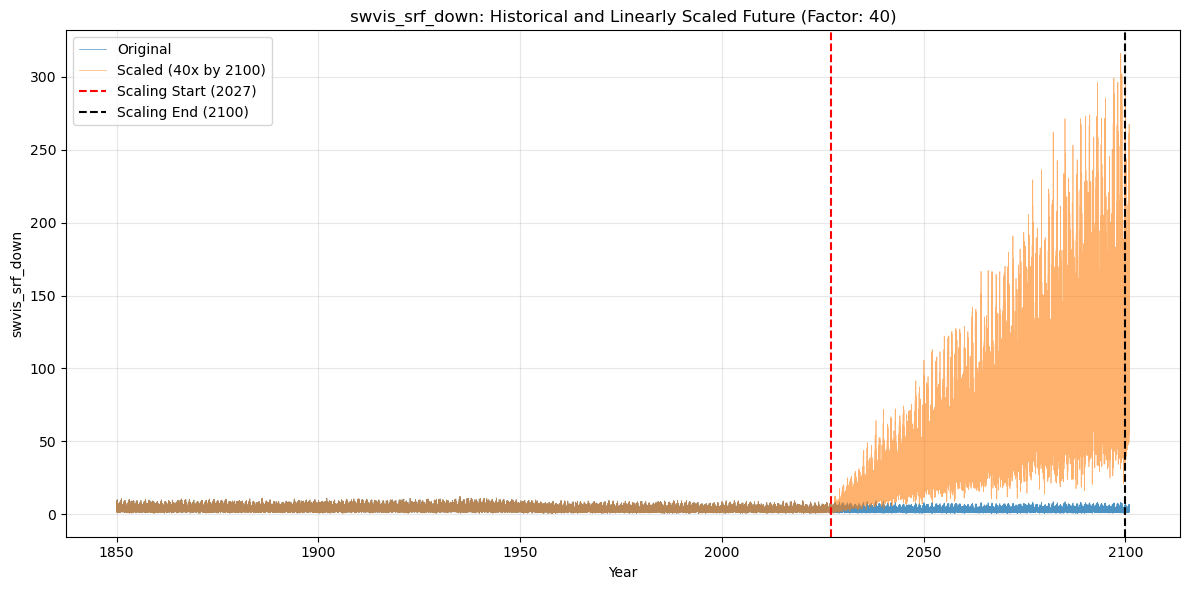

In [41]:
# 1. Create a distinct copy to keep the original untouched
df_scaled = df.copy()

# --- Configuration Variables ---
start_year = 2027
end_year = 2100
target_factor = 40  # Set your desired final multiplier here (e.g., 2.5 = 250%)
# -------------------------------

# 1. Calculate the fractional progress between start and end year (0.0 at 2027, 1.0 at 2100)
progress = (df_scaled['year'] - start_year) / (end_year - start_year)

# 2. Scale the progress by the total desired change 
# (e.g., if target_factor is 2.5, the total change is 1.5)
raw_multiplier = 1.0 + (progress * (target_factor - 1.0))

# 3. Clip the values to ensure it stays flat before start_year and after end_year
# Using min/max allows this to work for both increasing and decreasing factors
lower_bound = min(1.0, target_factor)
upper_bound = max(1.0, target_factor)
df_scaled['scaling_factor'] = np.clip(raw_multiplier, lower_bound, upper_bound)

# 4. Apply the scaling to the target variable
df_scaled['wind_air'] = df['wind_air'] * df_scaled['scaling_factor']
# Create a continuous time axis for cleaner plotting
df_scaled['decimal_year'] = df_scaled['year'] + (df_scaled['doy'] - 1) / 365.25

# --- Plotting ---
plt.figure(figsize=(12, 6))
plt.plot(df_scaled['decimal_year'], df['wind_air'], label='Original', alpha=0.8, linewidth=0.5)

# Dynamic label to reflect your chosen variable
plt.plot(df_scaled['decimal_year'], df_scaled['wind_air'], 
         label=f'Scaled ({target_factor}x by {end_year})', alpha=0.6, linewidth=0.5)

plt.title(f'swvis_srf_down: Historical and Linearly Scaled Future (Factor: {target_factor})')
plt.xlabel('Year')
plt.ylabel('swvis_srf_down')
plt.axvline(x=start_year, color='red', linestyle='--', label=f'Scaling Start ({start_year})')
plt.axvline(x=end_year, color='black', linestyle='--', label=f'Scaling End ({end_year})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# 1. Drop the temporary columns used for math and plotting
df_out = df_scaled.drop(columns=['scaling_factor', 'decimal_year'])

# 2. Convert the saved 'second_row' back into a 1-row DataFrame.
# By explicitly giving it the same column names as df_out, they will stack perfectly.
unit_row_df = pd.DataFrame([second_row.values], columns=df_out.columns)

# 3. Concatenate the unit row on top of the modified data
# This briefly converts the numeric columns to "object" types, which is fine for exporting to text.
final_df = pd.concat([unit_row_df, df_out], ignore_index=True)

# 4. Export to a new file with a whitespace delimiter (a single space)
# index=False ensures pandas doesn't write row numbers into the file
output_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai_jupyter_wind.dat"
final_df.to_csv(output_path, sep=" ", index=False)

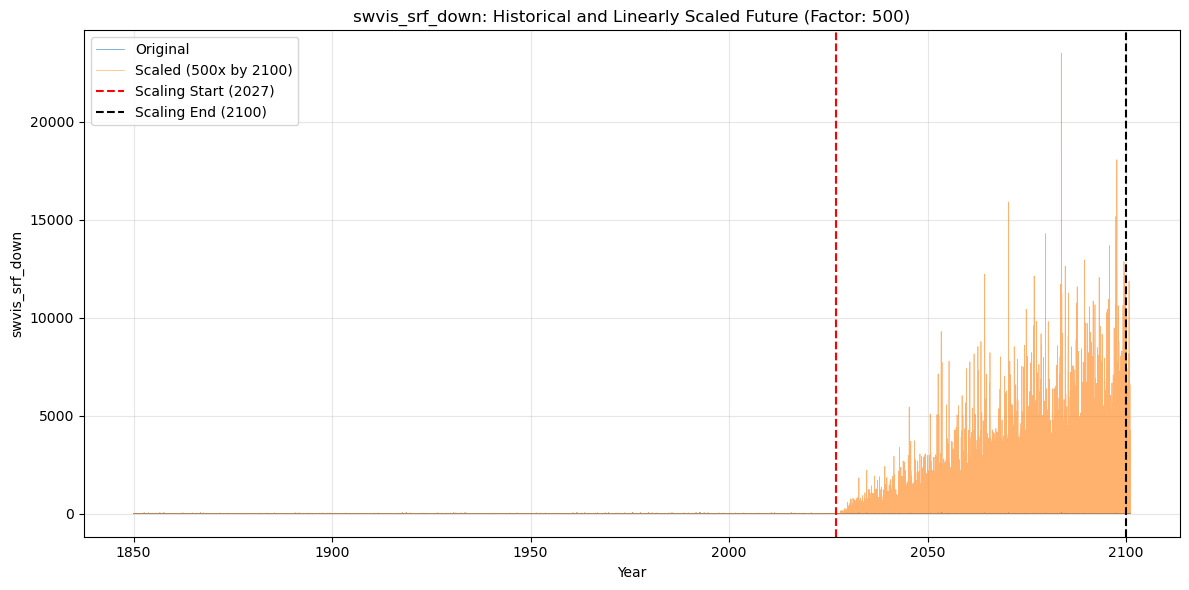

In [42]:
# 1. Create a distinct copy to keep the original untouched
df_scaled = df.copy()

# --- Configuration Variables ---
start_year = 2027
end_year = 2100
target_factor = 500  # Set your desired final multiplier here (e.g., 2.5 = 250%)
# -------------------------------

# 1. Calculate the fractional progress between start and end year (0.0 at 2027, 1.0 at 2100)
progress = (df_scaled['year'] - start_year) / (end_year - start_year)

# 2. Scale the progress by the total desired change 
# (e.g., if target_factor is 2.5, the total change is 1.5)
raw_multiplier = 1.0 + (progress * (target_factor - 1.0))

# 3. Clip the values to ensure it stays flat before start_year and after end_year
# Using min/max allows this to work for both increasing and decreasing factors
lower_bound = min(1.0, target_factor)
upper_bound = max(1.0, target_factor)
df_scaled['scaling_factor'] = np.clip(raw_multiplier, lower_bound, upper_bound)

# 4. Apply the scaling to the target variable
df_scaled['rain'] = df['rain'] * df_scaled['scaling_factor']
# Create a continuous time axis for cleaner plotting
df_scaled['decimal_year'] = df_scaled['year'] + (df_scaled['doy'] - 1) / 365.25

# --- Plotting ---
plt.figure(figsize=(12, 6))
plt.plot(df_scaled['decimal_year'], df['rain'], label='Original', alpha=0.8, linewidth=0.5)

# Dynamic label to reflect your chosen variable
plt.plot(df_scaled['decimal_year'], df_scaled['rain'], 
         label=f'Scaled ({target_factor}x by {end_year})', alpha=0.6, linewidth=0.5)

plt.title(f'swvis_srf_down: Historical and Linearly Scaled Future (Factor: {target_factor})')
plt.xlabel('Year')
plt.ylabel('swvis_srf_down')
plt.axvline(x=start_year, color='red', linestyle='--', label=f'Scaling Start ({start_year})')
plt.axvline(x=end_year, color='black', linestyle='--', label=f'Scaling End ({end_year})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# 1. Drop the temporary columns used for math and plotting
df_out = df_scaled.drop(columns=['scaling_factor', 'decimal_year'])

# 2. Convert the saved 'second_row' back into a 1-row DataFrame.
# By explicitly giving it the same column names as df_out, they will stack perfectly.
unit_row_df = pd.DataFrame([second_row.values], columns=df_out.columns)

# 3. Concatenate the unit row on top of the modified data
# This briefly converts the numeric columns to "object" types, which is fine for exporting to text.
final_df = pd.concat([unit_row_df, df_out], ignore_index=True)

# 4. Export to a new file with a whitespace delimiter (a single space)
# index=False ensures pandas doesn't write row numbers into the file
output_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai_water_GJ_1214b.dat"
final_df.to_csv(output_path, sep=" ", index=False)

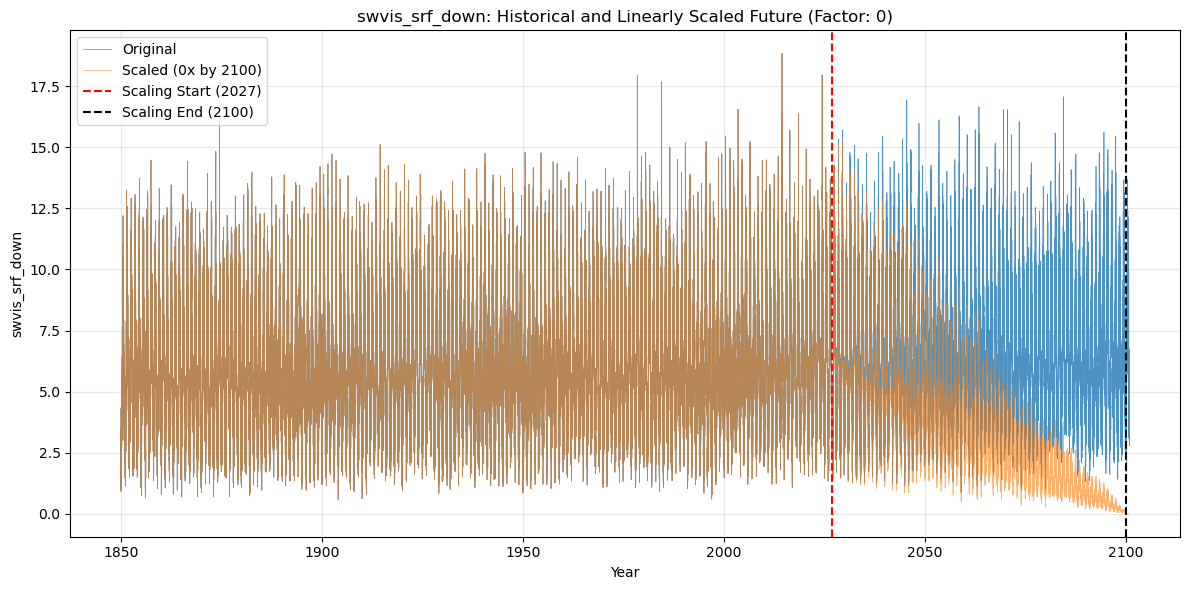

In [44]:
# 1. Create a distinct copy to keep the original untouched
df_scaled = df.copy()

# --- Configuration Variables ---
start_year = 2027
end_year = 2100
target_factor = 0  # Set your desired final multiplier here (e.g., 2.5 = 250%)
# -------------------------------

# 1. Calculate the fractional progress between start and end year (0.0 at 2027, 1.0 at 2100)
progress = (df_scaled['year'] - start_year) / (end_year - start_year)

# 2. Scale the progress by the total desired change 
# (e.g., if target_factor is 2.5, the total change is 1.5)
raw_multiplier = 1.0 + (progress * (target_factor - 1.0))

# 3. Clip the values to ensure it stays flat before start_year and after end_year
# Using min/max allows this to work for both increasing and decreasing factors
lower_bound = min(1.0, target_factor)
upper_bound = max(1.0, target_factor)
df_scaled['scaling_factor'] = np.clip(raw_multiplier, lower_bound, upper_bound)

# 4. Apply the scaling to the target variable
df_scaled['q_air'] = df['q_air'] * df_scaled['scaling_factor']
# Create a continuous time axis for cleaner plotting
df_scaled['decimal_year'] = df_scaled['year'] + (df_scaled['doy'] - 1) / 365.25

# --- Plotting ---
plt.figure(figsize=(12, 6))
plt.plot(df_scaled['decimal_year'], df['q_air'], label='Original', alpha=0.8, linewidth=0.5)

# Dynamic label to reflect your chosen variable
plt.plot(df_scaled['decimal_year'], df_scaled['q_air'], 
         label=f'Scaled ({target_factor}x by {end_year})', alpha=0.6, linewidth=0.5)

plt.title(f'swvis_srf_down: Historical and Linearly Scaled Future (Factor: {target_factor})')
plt.xlabel('Year')
plt.ylabel('swvis_srf_down')
plt.axvline(x=start_year, color='red', linestyle='--', label=f'Scaling Start ({start_year})')
plt.axvline(x=end_year, color='black', linestyle='--', label=f'Scaling End ({end_year})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# 1. Drop the temporary columns used for math and plotting
df_out = df_scaled.drop(columns=['scaling_factor', 'decimal_year'])

# 2. Convert the saved 'second_row' back into a 1-row DataFrame.
# By explicitly giving it the same column names as df_out, they will stack perfectly.
unit_row_df = pd.DataFrame([second_row.values], columns=df_out.columns)

# 3. Concatenate the unit row on top of the modified data
# This briefly converts the numeric columns to "object" types, which is fine for exporting to text.
final_df = pd.concat([unit_row_df, df_out], ignore_index=True)

# 4. Export to a new file with a whitespace delimiter (a single space)
# index=False ensures pandas doesn't write row numbers into the file
output_path = f"{root_path}/forcing_mpi-esm1-2_ssp126_DE-Hai_qsat_uranus.dat"
final_df.to_csv(output_path, sep=" ", index=False)